# 06 — Tổng hợp đánh giá & Bonus (so sánh 2026 vs 2025)

GIAI ĐOẠN 5 (Evaluation) + GIAI ĐOẠN 5-bonus: tổng hợp chỉ số đánh giá
của cả 3 bài toán, trả lời 3 câu hỏi nghiên cứu bằng bằng chứng, và thực
hiện phần bonus so sánh 2026 vs 2025 theo `decisions_log.md` DEC-002,
DEC-009.

In [1]:
import sys
sys.path.insert(0, "..")
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 80)

## 5.1 Bảng tổng hợp chỉ số đánh giá 3 bài toán

In [2]:
summary = pd.DataFrame([
    {
        "RQ": "RQ1 — Luật kết hợp",
        "Tiêu chí thành công": ">=10 luật lift>1.2 & confidence>0.5",
        "Kết quả": "479 luật (lift>1, confidence>0.6, đã loại luật hiển nhiên)",
        "Đạt?": "Đạt (vượt xa)",
    },
    {
        "RQ": "RQ2 — Phân cụm tỉnh",
        "Tiêu chí thành công": "Silhouette > 0.3",
        "Kết quả": "K-Means (PCA-5, k=4): Silhouette = 0.357",
        "Đạt?": "Đạt",
    },
    {
        "RQ": "RQ3 — Phát hiện bất thường",
        "Tiêu chí thành công": "Đồng thuận Jaccard >= 0.5 (IF vs LOF, top-N)",
        "Kết quả": "Jaccard = 0.32-0.36 (top-30)",
        "Đạt?": "Chưa đạt ngưỡng đề ra — 2 phương pháp bổ sung nhau hơn là trùng lặp hoàn toàn",
    },
])
summary

,RQ,Tiêu chí thành công,Kết quả,Đạt?
0,RQ1 — Luật kết hợp,>=10 luật lift>1.2 & confidence>0.5,"479 luật (lift>1, confidence>0.6, đã loại luật hiển nhiên)",Đạt (vượt xa)
1,RQ2 — Phân cụm tỉnh,Silhouette > 0.3,"K-Means (PCA-5, k=4): Silhouette = 0.357",Đạt
2,RQ3 — Phát hiện bất thường,"Đồng thuận Jaccard >= 0.5 (IF vs LOF, top-N)",Jaccard = 0.32-0.36 (top-30),Chưa đạt ngưỡng đề ra — 2 phương pháp bổ sung nhau hơn là trùng lặp hoàn toàn


## 5.2 Trả lời các câu hỏi nghiên cứu

### RQ1 — Thí sinh có xu hướng chọn những tổ hợp môn nào, và mức điểm các môn liên quan ra sao?

**Trả lời:** Có, rõ rệt. Hai tổ hợp môn tự chọn phổ biến nhất là Địa lý+Lịch sử (23,8% nhóm 2-môn-tự-chọn) và Vật lý+Hóa học (15,0%) — phản ánh 2 khối truyền thống Xã hội/Tự nhiên vẫn chi phối lựa chọn dù chương trình 2018 cho tự do kết hợp. Về điểm số: 479 luật kết hợp (lift 1-41) cho thấy (a) khó khăn học tập ở mức "Yếu" có xu hướng lan xuyên nhiều môn/khối hơn là cục bộ 1 môn, và (b) năng lực "Giỏi" đồng nhất rõ nhất trong khối Toán-Lý-Hóa truyền thống.

### RQ2 — Có thể nhóm 34 tỉnh/thành thành các cụm có đặc điểm điểm thi tương đồng không?

**Trả lời:** Có. K-Means (k=4, trên không gian PCA-5 chiều) đạt Silhouette=0,357, sinh ra 4 cụm có **tính địa lý - kinh tế rõ rệt** dù không dùng thông tin vùng miền làm đầu vào: Miền núi phía Bắc (điểm thấp nhất), Đô thị lớn & đồng bằng Bắc Bộ (điểm cao nhất), Nam Bộ/ĐBSCL (thiên tổ hợp Tự nhiên), Trung Bộ & Tây Nguyên (mức trung bình). Hierarchical (Ward) cho kết quả gần tương tự (ARI=0,84 so với K-Means), củng cố độ tin cậy của cấu trúc 4 cụm.

### RQ3 — Có đơn vị nào có phân bố điểm bất thường về mặt thống kê không?

**Trả lời:** Có một số tín hiệu đáng chú ý, nhưng **mức độ đồng thuận giữa các phương pháp ở mức vừa phải** (Jaccard 0,32-0,36), và **phụ thuộc đáng kể vào cách định nghĩa đơn vị nhóm** (Jaccard cấp tỉnh giữa site_id và cửa sổ trượt dao động 0,28-0,57). Phát hiện đáng tin cậy nhất là case 2 nhóm ở Phú Thọ, được cả Isolation Forest, LOF, và tác giả dữ liệu gốc (độc lập) cùng xác định — một dạng kiểm chứng chéo hiếm có. Hiện tượng dồn điểm Văn=5,0 xác nhận ở cấp quốc gia nhưng phân bố rất không đều giữa các tỉnh (1,0x đến 2,6x). **Tất cả chỉ là tín hiệu thống kê, không phải kết luận.**

## 5.3 Hạn chế tổng thể

1. Nguồn dữ liệu không chính thức (bên thứ ba thu thập từ trang tra cứu công khai), có thể thiếu một số thí sinh.
2. Không có thông tin nhân khẩu học (giới tính, loại trường, khu vực ưu tiên) — không thể diễn giải nguyên nhân sâu xa.
3. Không có ground-truth cho bài toán bất thường — chỉ đánh giá được bằng đồng thuận và độ ổn định giữa các phương pháp, không phải precision/recall.
4. Đơn vị "điểm thi" suy từ cấu trúc SBD là suy luận chưa xác nhận chính thức (DEC-003, DEC-007); kết quả RQ3 nhạy với lựa chọn này.
5. So sánh đa năm (bonus) chỉ thực hiện ở cấp quốc gia do bất tương thích mã tỉnh 2025 (63 mã cũ) vs 2026 (34 mã mới) — DEC-009.
6. Phân cụm tỉnh dựa trên PCA-5 (77,5% phương sai) — phần phương sai còn lại (22,5%) không được mô hình hóa, có thể ẩn chứa cấu trúc phụ.

---
## 8. (Bonus) So sánh 2026 vs 2025 — kỹ thuật nâng cao: phân tích so sánh trên các subset dữ liệu khác nhau

Dùng `diem_thi_2025_ct2018.csv` (kỳ thi 2025, cùng Chương trình GDPT 2018 — cấu trúc môn thi tương đồng nhất với 2026). **Chỉ so sánh ở cấp quốc gia** do bất tương thích mã tỉnh (DEC-009).

In [3]:
from src.preprocessing import load_raw_csv, ELECTIVE_SUBJECTS
from src.features import filter_standard_candidates, build_transactions_df
from src.association import run_fpgrowth, generate_rules, top_rules
from src.visualization import save_fig
import seaborn as sns

df26 = load_raw_csv("../data/raw/diem_thi_2026.csv")
df25 = load_raw_csv("../data/raw/diem_thi_2025_ct2018.csv")
print(f"2026: {len(df26):,} thí sinh | 2025: {len(df25):,} thí sinh")

2026: 1,208,863 thí sinh | 2025: 1,131,136 thí sinh


### 8.1 So sánh phổ điểm 2 môn bắt buộc

In [4]:
compare_scores = pd.DataFrame({
    "2025": [df25["toan"].mean(), df25["toan"].std(), df25["ngu_van"].mean(), df25["ngu_van"].std()],
    "2026": [df26["toan"].mean(), df26["toan"].std(), df26["ngu_van"].mean(), df26["ngu_van"].std()],
}, index=["Toan_mean", "Toan_std", "NguVan_mean", "NguVan_std"])
compare_scores["chenh_lech"] = compare_scores["2026"] - compare_scores["2025"]
compare_scores.round(3)

,2025,2026,chenh_lech
Toan_mean,4.783,5.652,0.868
Toan_std,1.677,1.893,0.216
NguVan_mean,7.002,6.497,-0.505
NguVan_std,1.279,1.324,0.046


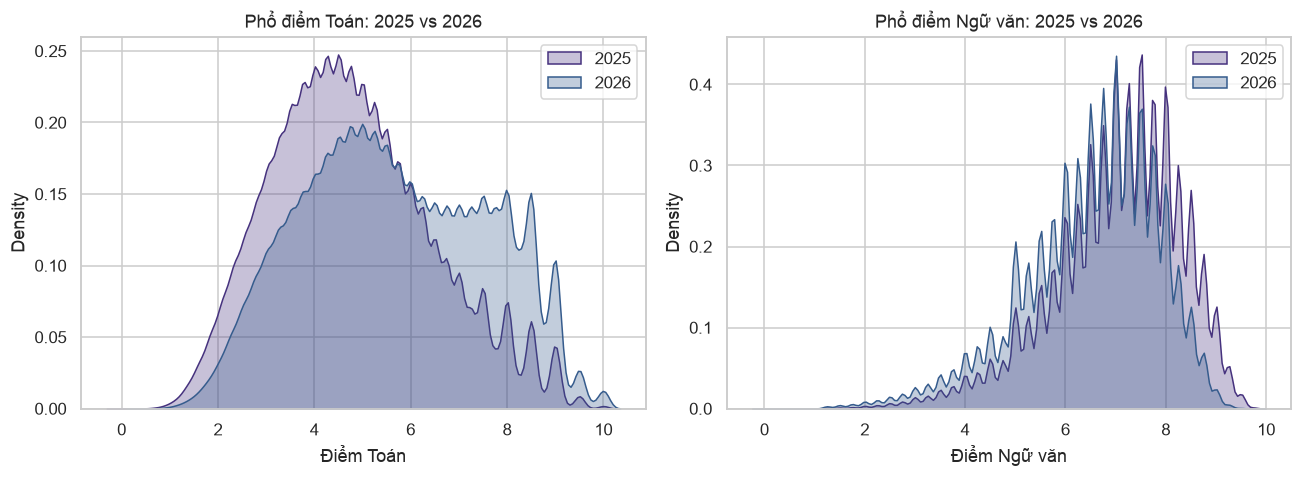

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col, label in zip(axes, ["toan", "ngu_van"], ["Toán", "Ngữ văn"]):
    sns.kdeplot(df25[col].dropna(), ax=ax, label="2025", fill=True, alpha=0.3)
    sns.kdeplot(df26[col].dropna(), ax=ax, label="2026", fill=True, alpha=0.3)
    ax.set_title(f"Phổ điểm {label}: 2025 vs 2026")
    ax.set_xlabel(f"Điểm {label}")
    ax.legend()
save_fig(fig, "06_so_sanh_pho_diem_2025_2026")
plt.show()

**Nhận xét:** Điểm Toán trung bình **tăng** đáng kể từ 4,78 (2025) lên
5,65 (2026, +0,87), trong khi Ngữ văn **giảm** nhẹ từ 7,00 xuống 6,50
(-0,50). Đây có thể phản ánh thay đổi độ khó đề thi giữa 2 năm hơn là
thay đổi năng lực thí sinh thực sự trong 1 năm — **không đủ căn cứ để
kết luận xu hướng dài hạn** (đúng hạn chế đã nêu ở mục 1.7).

### 8.2 So sánh tổ hợp môn tự chọn phổ biến

In [6]:
name_map = {
    "vat_ly": "Vật lý", "hoa_hoc": "Hóa học", "sinh_hoc": "Sinh học",
    "lich_su": "Lịch sử", "dia_ly": "Địa lý", "kinh_te_phap_luat": "GDKTPL",
    "tin_hoc": "Tin học", "cong_nghe_cong_nghiep": "CN Công nghiệp",
    "cong_nghe_nong_nghiep": "CN Nông nghiệp", "ngoai_ngu": "Ngoại ngữ",
}

def top_combo(df, n=6):
    mask2 = df[ELECTIVE_SUBJECTS].notna().sum(axis=1) == 2
    combo = df.loc[mask2, ELECTIVE_SUBJECTS].notna().apply(
        lambda r: " + ".join(name_map[c] for c in ELECTIVE_SUBJECTS if r[c]), axis=1
    )
    return (combo.value_counts(normalize=True) * 100).head(n)

compare_combo = pd.DataFrame({"2025_%": top_combo(df25), "2026_%": top_combo(df26)}).round(2)
compare_combo

,2025_%,2026_%
Lịch sử + GDKTPL,6.10,10.11
Lịch sử + Ngoại ngữ,6.42,7.48
Lịch sử + Địa lý,26.53,23.28
Vật lý + Hóa học,14.47,14.71
Vật lý + Ngoại ngữ,13.17,12.11
Địa lý + GDKTPL,9.76,8.68


**Nhận xét:** Thứ hạng tổ hợp phổ biến nhất **ổn định** qua 2 năm
(Lịch sử+Địa lý #1, Vật lý+Hóa học #2) — cho thấy lựa chọn tổ hợp môn
của thí sinh có tính bền vững, không biến động mạnh theo năm.

### 8.3 So sánh mẫu hình luật kết hợp

In [7]:
std25 = filter_standard_candidates(df25)
edges = [0, 5, 6.5, 8, 10.01]
labels = ["Yeu", "TrungBinh", "Kha", "Gioi"]
tx25 = build_transactions_df(std25, edges, labels)
onehot25 = pd.crosstab(tx25["sbd"], tx25["item"]).astype(bool)

itemsets25, _ = run_fpgrowth(onehot25, 0.01)
rules25 = generate_rules(itemsets25, min_confidence=0.6, min_lift=1.0)
print(f"2025: {len(rules25)} luật (lift>1) | 2026: 479 luật")
top_rules(rules25, 8)

2025: 591 luật (lift>1) | 2026: 479 luật


,antecedents_str,consequents_str,support,confidence,lift,conviction
0,"Chon_HoaHoc, Chon_VatLy, Toan_Gioi","HoaHoc_Gioi, VatLy_Gioi",0.013815,0.616252,25.843945,2.543736
2,"Chon_HoaHoc, Chon_VatLy, Toan_Gioi, VatLy_Gioi",HoaHoc_Gioi,0.013815,0.724969,17.701316,3.487045
1,"Chon_HoaHoc, Toan_Gioi, VatLy_Gioi",HoaHoc_Gioi,0.013815,0.724969,17.701316,3.487045
3,"Chon_HoaHoc, Toan_Gioi",HoaHoc_Gioi,0.020068,0.688624,16.813891,3.080022
4,"Chon_HoaHoc, NguVan_Kha, Toan_Gioi",HoaHoc_Gioi,0.010395,0.678861,16.575501,2.986382
5,"Chon_HoaHoc, Chon_VatLy, Toan_Gioi",HoaHoc_Gioi,0.014838,0.661854,16.160246,2.836182
6,"Chon_HoaHoc, NguVan_TrungBinh, Toan_Yeu",HoaHoc_Yeu,0.011068,0.728316,11.565727,3.448965
7,"Chon_HoaHoc, Toan_Yeu, VatLy_TrungBinh",HoaHoc_Yeu,0.010871,0.696727,11.064087,3.089718


**Nhận xét:** Mẫu hình luật của 2025 **nhất quán với 2026** — luật lift
cao nhất vẫn tập trung ở cụm Toán-Lý-Hóa (khối A truyền thống), cả 2
chiều "Giỏi cùng nhau" (lift ~17-26) và "Yếu cùng nhau" (lift ~10-11).
Điều này củng cố độ tin cậy của kết luận RQ1: **tương quan năng lực
giữa các môn trong cùng khối thi mang tính cấu trúc ổn định**, không
phải đặc thù riêng của một năm.

### Tóm tắt giá trị của phần bonus

Kỹ thuật "so sánh trên các subset dữ liệu khác nhau" (2025 vs 2026) giúp
**phân biệt điều gì ổn định (cấu trúc tương quan môn, thứ hạng tổ hợp
phổ biến) với điều gì biến động theo năm (mức điểm tuyệt đối, có thể do
độ khó đề thi)** — một mức hiểu sâu hơn so với chỉ phân tích 1 năm duy
nhất, dù phạm vi so sánh bị giới hạn ở cấp quốc gia do bất tương thích
mã tỉnh giữa 2 năm.